# 10 — LSTM 2014 Backtest

Stage 11. Scores the selected LSTM on the 2014 test year with the same protocol as
XGBoost: 12 monthly expanding-window refits with the configuration frozen after the
2013 tuning, scored on the common eval hours. Then the Diebold–Mariano test against
XGBoost and persistence, and the error by PM2.5 level — including the extreme hours
where Phase 1 struggled.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, validate
from src import windows as W, protocol as P
from src.dl_models import LSTMForecaster
from src.evaluate import metrics, diebold_mariano
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)

cfg = json.load(open(ROOT / 'results' / 'metrics' / 'lstm_selected_config.json'))
LB = cfg['lookback']
params = {k: cfg[k] for k in ['formulation', 'hidden', 'layers', 'dropout', 'lr', 'weight_decay', 'epochs', 'seed']}
print('frozen config:', cfg['lookback'], 'h |', params)

X, y, split, mask, stats = W.build_sequence_dataset(df, lookback=LB)
pm_t = df['pm25'].ffill().reindex(mask.index).to_numpy('float32')
index = mask.index

# Phase 1 test predictions on the identical eval hours
phase1 = pd.read_csv(ROOT / 'results' / 'predictions' / 'test_2014.csv', parse_dates=['issue_time', 'target_time'])
phase1 = phase1.set_index('issue_time')
print('phase 1 test rows:', len(phase1))

frozen config: 24 h | {'formulation': 'delta', 'hidden': 64, 'layers': 2, 'dropout': 0.1, 'lr': 0.001, 'weight_decay': 0.0001, 'epochs': 40, 'seed': 0}
phase 1 test rows: 8531


## 1. Monthly backtest

Each month is forecast by a model refit on every target hour before that month, with
the frozen configuration. Predictions are collected on the common eval hours only, so
they line up one-to-one with the XGBoost test predictions.

In [2]:
folds = P.backtest_folds('2014-01-01', '2014-12-31 23:00')      # 12 monthly folds
mask_np = mask.to_numpy()

preds, rows = [], []
for f in folds:
    train, test = P.fold_masks(index, f)
    tr = train.to_numpy() & ~np.isnan(y) & ~np.isnan(pm_t)
    te = test.to_numpy() & mask_np
    t0 = time.time()
    model = LSTMForecaster(**params).fit(X[tr], y[tr], pm_t[tr])
    p = model.predict(X[te], pm_t[te])
    preds.append(pd.Series(p, index=index[te]))
    m = metrics(y[te], p)
    rows.append({'fold': f['fold'], 'test_start': f['test_start'].date(), 'test_end': f['test_end'].date(),
                 'n_train': int(model.n_train_), **m})
    print(f"fold {f['fold']:2d}  {f['test_start'].date()}  n={m['n']:4d}  MAE={m['MAE']:.3f}  ({time.time()-t0:.0f}s)")

lstm_pred = pd.concat(preds).rename('lstm')
monthly = pd.DataFrame(rows)
monthly.to_csv(ROOT / 'results' / 'metrics' / 'lstm_test_monthly.csv', index=False)

out = phase1.join(lstm_pred)       # align LSTM onto the Phase 1 eval hours
out[['target_time', 'y_true', 'persistence', 'xgboost', 'lstm']].to_csv(ROOT / 'results' / 'predictions' / 'lstm_test_2014.csv')
print('aligned rows:', out['lstm'].notna().sum(), '/', len(out))
monthly.round(3)

fold  1  2014-01-01  n= 728  MAE=16.491  (19s)


fold  2  2014-02-01  n= 663  MAE=14.423  (19s)


fold  3  2014-03-01  n= 741  MAE=11.922  (19s)


fold  4  2014-04-01  n= 712  MAE=11.887  (18s)


fold  5  2014-05-01  n= 739  MAE=10.464  (27s)


fold  6  2014-06-01  n= 682  MAE=8.738  (21s)


... (3 outputs left out)

fold 10  2014-10-01  n= 741  MAE=10.618  (17s)


fold 11  2014-11-01  n= 689  MAE=12.127  (59s)


fold 12  2014-12-01  n= 683  MAE=11.826  (37s)
aligned rows: 8531 / 8531


,fold,test_start,test_end,n_train,n,MAE,RMSE,R2
0,1,2014-01-01,2014-01-31,33095,728,16.491,31.639,0.919
1,2,2014-02-01,2014-02-28,33832,663,14.423,24.456,0.972
2,3,2014-03-01,2014-03-31,34501,741,11.922,20.429,0.956
3,4,2014-04-01,2014-04-30,35244,712,11.887,27.318,0.774
4,5,2014-05-01,2014-05-31,35961,739,10.464,18.542,0.831
5,6,2014-06-01,2014-06-30,36703,682,8.738,13.558,0.897
6,7,2014-07-01,2014-07-31,37406,728,9.193,12.970,0.960
7,8,2014-08-01,2014-08-31,38143,720,9.127,14.657,0.891
8,9,2014-09-01,2014-09-30,38876,705,8.645,13.468,0.921
9,10,2014-10-01,2014-10-31,39591,741,10.618,16.300,0.981


## 2. Pooled test results

All models on the same 2014 eval hours.

In [3]:
y_true = out['y_true'].to_numpy()
comp = pd.DataFrame([
    {'model': 'persistence', **metrics(y_true, out['persistence'])},
    {'model': 'XGBoost (change)', **metrics(y_true, out['xgboost'])},
    {'model': 'LSTM', **metrics(y_true, out['lstm'])},
]).set_index('model')
comp.to_csv(ROOT / 'results' / 'metrics' / 'lstm_test_pooled.csv')
comp[['n', 'MAE', 'RMSE', 'R2']].round(3)

,n,MAE,RMSE,R2
model,,,,
persistence,8531,11.926,22.033,0.944
XGBoost (change),8531,10.959,19.956,0.954
LSTM,8531,11.279,20.493,0.952


## 3. Diebold–Mariano test

Equal predictive accuracy on the 2014 eval hours (Newey–West long-run variance). A
negative statistic means the first model has the lower loss.

In [4]:
e_lstm = y_true - out['lstm'].to_numpy()
e_xgb = y_true - out['xgboost'].to_numpy()
e_pers = y_true - out['persistence'].to_numpy()

dm = []
for name, e2 in [('LSTM vs XGBoost', e_xgb), ('LSTM vs persistence', e_pers)]:
    for loss in ['squared', 'absolute']:
        stat, p = diebold_mariano(e_lstm, e2, loss=loss)
        dm.append({'comparison': name, 'loss': loss, 'DM': stat, 'p-value': p})
dm = pd.DataFrame(dm)
dm.to_csv(ROOT / 'results' / 'metrics' / 'lstm_diebold_mariano.csv', index=False)
dm.round(4)

,comparison,loss,DM,p-value
0,LSTM vs XGBoost,squared,2.1267,0.0334
1,LSTM vs XGBoost,absolute,4.2882,0.0000
2,LSTM vs persistence,squared,-5.5356,0.0000
3,LSTM vs persistence,absolute,-6.1708,0.0000


## 4. Error by PM2.5 level

The same bands as Phase 1. The extreme band (> 250 µg/m³) is where XGBoost did not beat
persistence, so it is the first place to look for the LSTM — and the target for the
hybrid next.

In [5]:
bands = pd.cut(out['y_true'], [0, 35, 75, 150, 250, np.inf],
               labels=['0-35', '35-75', '75-150', '150-250', '>250'])
def band_rows(g):
    yt = g['y_true'].to_numpy()
    return pd.Series({'hours': len(g),
                      'RMSE pers': metrics(yt, g['persistence'])['RMSE'],
                      'RMSE xgb': metrics(yt, g['xgboost'])['RMSE'],
                      'RMSE lstm': metrics(yt, g['lstm'])['RMSE'],
                      'MAE pers': metrics(yt, g['persistence'])['MAE'],
                      'MAE xgb': metrics(yt, g['xgboost'])['MAE'],
                      'MAE lstm': metrics(yt, g['lstm'])['MAE']})
by_level = out.groupby(bands, observed=True).apply(band_rows)
by_level.to_csv(ROOT / 'results' / 'metrics' / 'lstm_test_by_level.csv')
by_level.round(2)

,hours,RMSE pers,RMSE xgb,RMSE lstm,MAE pers,MAE xgb,MAE lstm
y_true,,,,,,,
0-35,2485.0,12.08,10.47,11.41,5.64,5.48,5.86
35-75,1937.0,18.90,15.66,16.45,10.61,9.39,9.75
75-150,2399.0,20.23,18.10,18.48,13.14,11.82,11.95
150-250,1061.0,30.46,26.01,26.78,18.83,16.78,17.29
>250,649.0,41.56,42.04,42.16,24.18,23.92,24.28


## 5. Figures

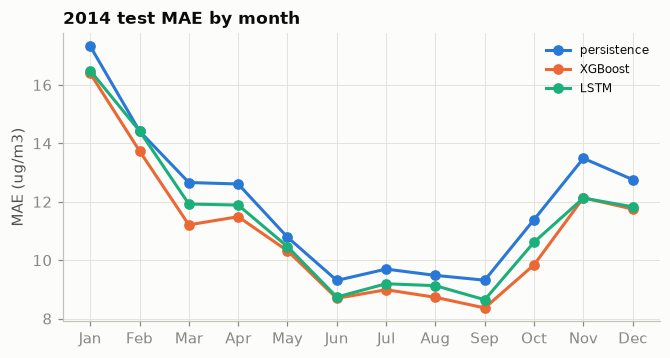

In [6]:
# monthly MAE for the three models
order = out['target_time'].dt.month
mae_by_month = {}
for col, name in [('persistence', 'persistence'), ('xgboost', 'XGBoost'), ('lstm', 'LSTM')]:
    mae_by_month[name] = out.assign(m=order).groupby('m').apply(
        lambda g: metrics(g['y_true'].to_numpy(), g[col])['MAE'])

fig, ax = plt.subplots(figsize=(7, 3.4))
months = sorted(order.unique())
xticklabels = [pd.Timestamp(2014, m, 1).strftime('%b') for m in months]
for i, (name, s) in enumerate(mae_by_month.items()):
    ax.plot(months, s.reindex(months).to_numpy(), marker='o', color=ps.SERIES[i], label=name)
ax.set_xticks(months); ax.set_xticklabels(xticklabels)
ax.set_ylabel('MAE (ug/m3)'); ax.set_title('2014 test MAE by month'); ax.legend(fontsize=8)
ps.save(fig, 'dl_03_test_monthly'); plt.show()

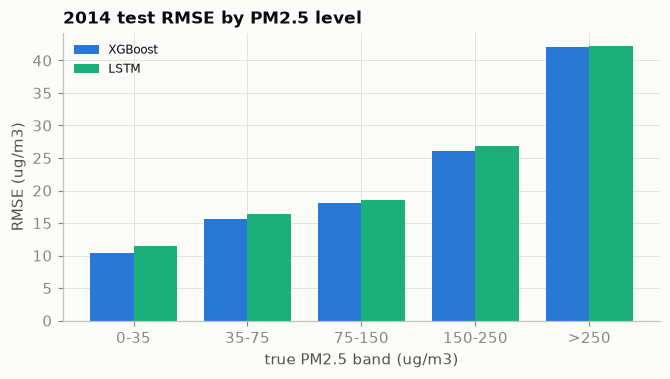

In [7]:
# RMSE by level: XGBoost vs LSTM
b = by_level.reset_index().rename(columns={'index': 'band'})
xpos = np.arange(len(b)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(xpos - w/2, b['RMSE xgb'], w, color=ps.SERIES[0], label='XGBoost')
ax.bar(xpos + w/2, b['RMSE lstm'], w, color=ps.SERIES[2], label='LSTM')
ax.set_xticks(xpos); ax.set_xticklabels(b.iloc[:, 0])
ax.set_xlabel('true PM2.5 band (ug/m3)'); ax.set_ylabel('RMSE (ug/m3)')
ax.set_title('2014 test RMSE by PM2.5 level'); ax.legend(fontsize=8)
ps.save(fig, 'dl_04_test_by_level'); plt.show()